In [2]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

In [3]:
# --------------------------------------------------
# STEP 1: LOAD THE DATASET
# --------------------------------------------------

# 1E: Sign Language MNIST Dataset
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

In [4]:

x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

# Convert labels into consecutive values (0 to 23)
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

In [5]:
# --------------------------------------------------
# STEP 2: PREPROCESS THE DATA
# --------------------------------------------------

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') /255.0
x_test = x_test.astype('float32') /255.0

# Flatten images into 1D vectors
x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)


In [6]:
# --------------------------------------------------
# STEP 3: DEFINE THE FNN MODEL
# --------------------------------------------------

model = keras.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(24, activation='softmax')
])

In [7]:
# --------------------------------------------------
# STEP 4: COMPILE THE MODEL
# --------------------------------------------------

model.compile(
    optimizer=keras.optimizers.Adam(),
    # Alternatively: optimizer=keras.optimizers.Adam()
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
# --------------------------------------------------
# STEP 5: TRAIN THE MODEL
# --------------------------------------------------

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.3508 - loss: 2.0950 - val_accuracy: 0.5484 - val_loss: 1.4518
Epoch 2/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6186 - loss: 1.1993 - val_accuracy: 0.7014 - val_loss: 0.9453
Epoch 3/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7360 - loss: 0.8348 - val_accuracy: 0.7873 - val_loss: 0.6755
Epoch 4/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8128 - loss: 0.5969 - val_accuracy: 0.8288 - val_loss: 0.5149
Epoch 5/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8654 - loss: 0.4335 - val_accuracy: 0.8543 - val_loss: 0.4424
Epoch 6/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9073 - loss: 0.3087 - val_accuracy: 0.8627 - val_loss: 0.3683
Epoch 7/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9325 - loss: 0.2310 - val_accuracy: 0.9188 - val_loss: 0.2602
Epoch 8/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9498 - loss: 0.1770 - val_accu

In [9]:
# --------------------------------------------------
# STEP 6: EVALUATE THE MODEL
# --------------------------------------------------

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7112 - loss: 1.3540
Test Loss: 1.353980302810669
Test Accuracy: 71.1238145828247 %


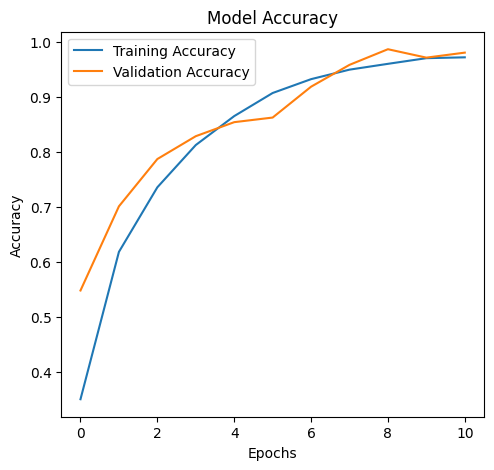

In [10]:
# --------------------------------------------------
# STEP 7: PLOT TRAINING LOSS AND ACCURACY
# --------------------------------------------------

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

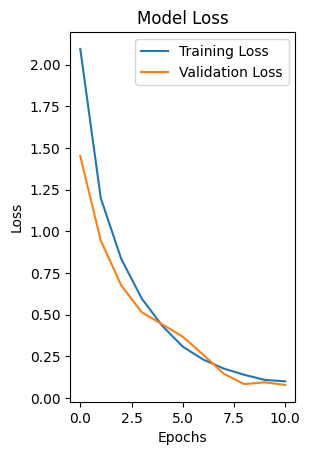

In [11]:
# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()